# 14 · Recommendations without future leakage

## The engineering question
Does a content-similarity recommender find useful eligible items without learning from the future?

**Learning outcomes:** construct profiles from pre-cutoff interactions; exclude owned, unavailable, and incompatible items; compare popularity, content retrieval, and diversity; measure recommendation hit rate and catalog coverage.

The fictional catalog has travel and office accessories. Each user's next interaction occurs after a fixed cutoff. We build both the content profile and popularity baseline only from earlier interactions. Descriptions are item features, while future interactions are labels. A future product is present as a deliberate leakage trap and must never become an eligible recommendation at the earlier timestamp.

The user profile is the normalized mean of owned-item embeddings. Qdrant retrieves eligible vectors; MMR diversifies the returned candidates. This is a tiny content-based demonstration, not collaborative filtering or a customer-preference study. Two synthetic users provide diagnostic examples, not statistically reliable product quality.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from vector_masterclass.lesson import LessonRun
from vector_masterclass.config import root

plt.rcParams.update(
    {"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False}
)
lesson = LessonRun("14", "B", docker=True)
print("Kernel:", sys.executable)
print("Workspace:", root())

Kernel: /Users/markcastillo/git/vector-masterclass/.venv/bin/python3
Workspace: /Users/markcastillo/git/vector-masterclass


In [2]:
import json

fixtures = json.loads((root() / "datasets/applications.json").read_text())

,user,method,recommended,future_positive_items,hit_at_3,catalog_coverage,family_diversity,exclusions_hold
0,traveler,popularity,"[ethernet, power-bank, router-case]",[router-case],True,0.75,3,True
1,traveler,content,"[router-case, usb-cable, power-bank]",[router-case],True,0.75,2,True
2,traveler,diverse content,"[router-case, power-bank, usb-cable]",[router-case],True,0.75,2,True
3,operator,popularity,"[ethernet, fan, rack-kit]",[rack-kit],True,1.00,3,True
4,operator,content,"[rack-kit, fan, ethernet]",[rack-kit],True,1.00,3,True
5,operator,diverse content,"[rack-kit, fan, ethernet]",[rack-kit],True,1.00,3,True


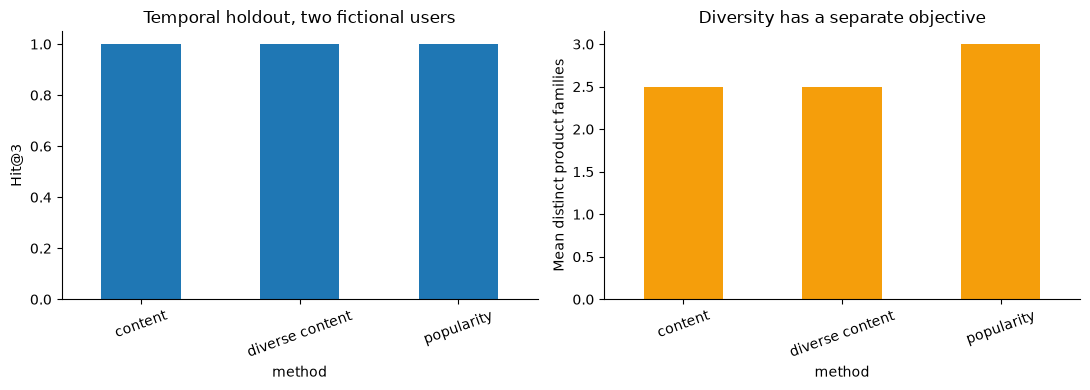

In [3]:
from uuid import uuid4
from collections import Counter
from vector_masterclass.schema import Document
from vector_masterclass.chunking import chunk_document
from vector_masterclass.models import embed
from vector_masterclass.retrieval import normalized, mmr
from vector_masterclass.store import VectorIndex, tenant_filter

cfg = fixtures["recommendation"]
catalog = {item["id"]: item for item in cfg["catalog"]}
docs = [
    Document(
        id=i["id"],
        revision="1",
        title=i["id"],
        text=i["text"],
        published=i["published"],
        family=i["family"],
    )
    for i in catalog.values()
]
matrix = embed([d.text for d in docs])
by_id = {d.id: matrix[i] for i, d in enumerate(docs)}
historical = [e for e in cfg["interactions"] if e["date"] < cfg["cutoff"]]
popularity = Counter(e["item"] for e in historical)
index = VectorIndex("vmc_14_" + uuid4().hex[:8])
index.create()
rows = []
try:
    for doc in docs:
        index.upsert(chunk_document(doc, "document"), document_id=doc.id, include_sparse=False)
    for user in cfg["users"]:
        owned = {e["item"] for e in historical if e["user"] == user["id"]}
        future = {
            e["item"]
            for e in cfg["interactions"]
            if e["user"] == user["id"] and e["date"] >= cfg["cutoff"]
        }
        eligible = {
            id_
            for id_, item in catalog.items()
            if id_ not in owned
            and item["published"] < cfg["cutoff"]
            and user["context"] in item["compatible"]
        }
        profile = normalized(np.mean([by_id[id_] for id_ in sorted(owned)], axis=0))
        response = index.client.query_points(
            index.name,
            query=profile.tolist(),
            using="dense",
            query_filter=tenant_filter("public", [id_ + "@1" for id_ in eligible]),
            limit=20,
            with_payload=True,
        )
        candidates = [p.payload["document_id"] for p in response.points]
        diverse = [
            candidates[i]
            for i in mmr(profile, np.array([by_id[id_] for id_ in candidates]), k=3, weight=0.6)
        ]
        variants = {
            "popularity": sorted(eligible, key=lambda id_: (-popularity[id_], id_))[:3],
            "content": candidates[:3],
            "diverse content": diverse,
        }
        for method, ids in variants.items():
            rows.append(
                {
                    "user": user["id"],
                    "method": method,
                    "recommended": ids,
                    "future_positive_items": sorted(future),
                    "hit_at_3": bool(set(ids) & future),
                    "catalog_coverage": len(set(ids)) / len(eligible),
                    "family_diversity": len({catalog[id_]["family"] for id_ in ids}),
                    "exclusions_hold": set(ids).issubset(eligible) and not set(ids) & owned,
                }
            )
finally:
    index.drop()
    index.close()
results = lesson.table(pd.DataFrame(rows))
display(results)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
results.groupby("method").hit_at_3.mean().plot.bar(ax=axes[0])
results.groupby("method").family_diversity.mean().plot.bar(ax=axes[1], color="#f59e0b")
axes[0].set(ylabel="Hit@3", ylim=(0, 1.05), title="Temporal holdout, two fictional users")
axes[1].set(ylabel="Mean distinct product families", title="Diversity has a separate objective")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
lesson.figure(fig)
plt.show()

## Interpretation and exercise
A relevant recommendation can lose to an ineligible near neighbor unless exclusions are enforced within retrieval. Popularity provides a strong cheap baseline but cannot personalize an unusual preference. Content methods address some cold-start items but still need a useful user profile. Diversity may improve catalog coverage while lowering short-term clicks; choose the objective explicitly.

**Exercise:** move the future case's publication date before the cutoff and observe eligibility. Then accidentally include the post-cutoff click in the profile and explain why the apparent quality gain is leakage. Propose a cold-start fallback for a user with no history and keep eligibility checks on that path.

Production recommendation evaluation also needs exposure bias, negative sampling, repeat purchases, inventory changes, exploration, and online outcome measurement. An unclicked item is not automatically a true negative. These labels are author-created instructional fixtures.

In [4]:
manifest = lesson.finish(
    {
        "all_exclusions_hold": bool(results.exclusions_hold.all()),
        "future_item_excluded": all("future-case" not in ids for ids in results.recommended),
        "training_precedes_cutoff": all(e["date"] < cfg["cutoff"] for e in historical),
        "three_baselines": results.method.nunique() == 3,
    },
    observations={
        "cutoff": cfg["cutoff"],
        "evaluation_users": 2,
        "label_provenance": fixtures["provenance"],
        "recommendation_k": 3,
    },
)

{
  "artifact": "artifacts/20261031T054312Z-706616/14",
  "checks": {
    "all_exclusions_hold": true,
    "future_item_excluded": true,
    "training_precedes_cutoff": true,
    "three_baselines": true,
    "process_memory_measured": true,
    "qdrant_memory_measured_when_required": true,
    "within_runtime_target": true,
    "within_conservative_memory_target": true
  }
}


## References and next steps
Consult the [Qdrant documentation](https://qdrant.tech/documentation/),
the [MiniLM model card](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2),
and [uv's Jupyter guide](https://docs.astral.sh/uv/guides/integration/jupyter/).
The exact pinned configuration is in `configs/models.json`; worked exercises are in `docs/SOLUTIONS.md`.
This notebook's measurements apply to the recorded local run, not a production deployment.